In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay

# data

In [43]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Files/heart.csv")
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125.0,212,0,NaN,168.0,0,1.0,2,2.0,3.0,0
1,53,1,0,140.0,203,1,0.0,155.0,1,3.1,0,0.0,3.0,0
2,70,1,0,145.0,174,0,1.0,125.0,1,2.6,0,0.0,3.0,0
3,61,1,0,148.0,203,0,1.0,NaN,0,0.0,2,1.0,3.0,0
4,62,0,0,138.0,294,1,1.0,106.0,0,1.9,1,3.0,2.0,0
5,58,0,0,100.0,248,0,0.0,122.0,0,1.0,1,0.0,2.0,1
6,58,1,0,114.0,318,0,2.0,140.0,0,4.4,0,NaN,1.0,0
7,55,1,0,160.0,289,0,0.0,145.0,1,0.8,1,1.0,3.0,0
8,46,1,0,120.0,249,0,0.0,144.0,0,0.8,2,0.0,3.0,0
9,54,1,0,122.0,286,0,0.0,116.0,1,3.2,1,2.0,2.0,0


# Data properties

In [44]:
df.shape

(1025, 14)

In [45]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1024.000000,1025.00000,1025.000000,1024.000000,1024.000000,1025.000000,1025.000000,1025.000000,1023.000000,1024.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.603516,246.00000,0.149268,0.529297,149.102539,0.336585,1.071512,1.385366,0.752688,2.324219,0.513171
std,9.072290,0.460373,1.029641,17.523313,51.59251,0.356527,0.527931,23.013962,0.472772,1.175053,0.617755,1.029140,0.620881,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [46]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1024 non-null   float64
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1024 non-null   float64
 7   thalach   1024 non-null   float64
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1023 non-null   float64
 12  thal      1024 non-null   float64
 13  target    1025 non-null   int64  
dtypes: float64(6), int64(8)
memory usage: 112.2 KB


In [48]:
df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,1
chol,0
fbs,0
restecg,1
thalach,1
exang,0
oldpeak,0


# Handle Missing Values

In [49]:
#df['trestbps'].unique()

In [50]:
df['trestbps'].fillna(df['restecg'].median(),inplace=True)

/tmp/ipykernel_3696/3162408844.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['trestbps'].fillna(df['restecg'].median(),inplace=True)


In [51]:
# df['thalach']

In [52]:
df['thalach'].fillna(df['thalach'].mean(),inplace=True)

/tmp/ipykernel_3696/1554764962.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['thalach'].fillna(df['thalach'].mean(),inplace=True)


In [53]:
# df['ca'].head(10)

In [54]:
df['ca'].fillna(df['ca'].mode()[0],inplace=True)

/tmp/ipykernel_3696/2833728961.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['ca'].fillna(df['ca'].mode()[0],inplace=True)


In [55]:
df['restecg'].unique()

array([nan,  0.,  1.,  2.])

In [56]:
df['restecg'].fillna(df['restecg'].mode()[0],inplace=True)

/tmp/ipykernel_3696/3144305946.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['restecg'].fillna(df['restecg'].mode()[0],inplace=True)


In [57]:
df['thal'].unique()

array([ 3.,  2.,  1.,  0., nan])

In [58]:
df['thal'].fillna(df['thal'].mode()[0],inplace=True)

/tmp/ipykernel_3696/1253415530.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['thal'].fillna(df['thal'].mode()[0],inplace=True)


In [59]:
sum(df.isna().sum())

0

# Data Exploration

In [60]:
df['target'].value_counts()

,count
target,
1,526
0,499


<Axes: xlabel='target', ylabel='count'>

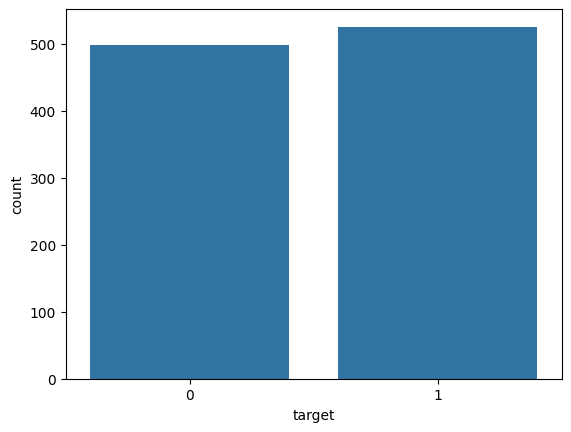

In [61]:
sns.countplot(data=df,x=df['target'])

In [62]:

# plt.figure(figsize=(10,10))
# sns.boxplot(df)
# plt.show()

# Data Preprocessing

In [63]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125.0,212,0,1.0,168.000000,0,1.0,2,2.0,3.0,0
1,53,1,0,140.0,203,1,0.0,155.000000,1,3.1,0,0.0,3.0,0
2,70,1,0,145.0,174,0,1.0,125.000000,1,2.6,0,0.0,3.0,0
3,61,1,0,148.0,203,0,1.0,149.102539,0,0.0,2,1.0,3.0,0
4,62,0,0,138.0,294,1,1.0,106.000000,0,1.9,1,3.0,2.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140.0,221,0,1.0,164.000000,1,0.0,2,0.0,2.0,1
1021,60,1,0,125.0,258,0,0.0,141.000000,1,2.8,1,1.0,3.0,0
1022,47,1,0,110.0,275,0,0.0,118.000000,1,1.0,1,1.0,2.0,0
1023,50,0,0,110.0,254,0,0.0,159.000000,0,0.0,2,0.0,2.0,1


In [64]:
x=df.iloc[:,:-1].values
y=df.iloc[:,-1].values

# Features Normalisation

In [65]:
scaler = StandardScaler()
scaler.fit(x)
x=scaler.transform(x)

# Split Train Data

In [66]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.33,random_state=42)

In [67]:
# x_train

# Build Model

In [68]:
model = KNeighborsClassifier(n_neighbors=13)
model.fit(x_train,y_train)


KNeighborsClassifier(n_neighbors=13)

In [69]:
y_pred = model.predict(x_test)
y_pred

array([1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0,
       1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1,

# Confution Metrix

In [70]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[138,  33],
       [ 20, 148]])

In [71]:
# y_train

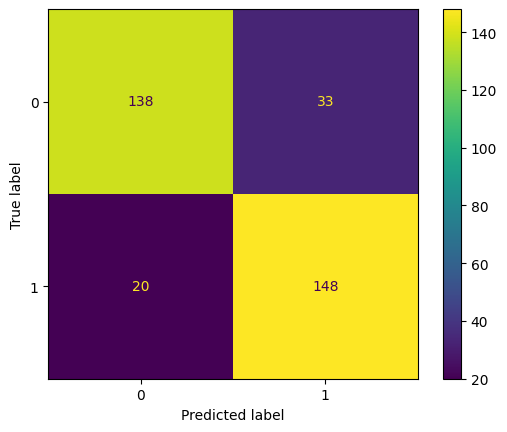

In [72]:

cmd = ConfusionMatrixDisplay(cm)
cmd.plot()

# Accuracy

In [73]:
score = accuracy_score(y_pred,y_test)
score

0.8436578171091446

In [74]:
for i in range(5,21):
  model = KNeighborsClassifier(n_neighbors=i)
  model.fit(x_train,y_train)
  y_pred = model.predict(x_test)
  score = accuracy_score(y_pred,y_test)
  print(i,"=",score)

5 = 0.8613569321533924
6 = 0.8584070796460177
7 = 0.8584070796460177
8 = 0.855457227138643
9 = 0.8436578171091446
10 = 0.8495575221238938
11 = 0.8466076696165191
12 = 0.8525073746312685
13 = 0.8436578171091446
14 = 0.8525073746312685
15 = 0.8436578171091446
16 = 0.8407079646017699
17 = 0.8436578171091446
18 = 0.8436578171091446
19 = 0.8495575221238938
20 = 0.8377581120943953


# Tuning

In [75]:
from sklearn.model_selection import GridSearchCV

In [76]:
model1 = KNeighborsClassifier()

In [77]:
data = {
    "n_neighbors": [3, 5, 7, 9, 11, 15],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"],
    "p": [1, 2]
}

In [78]:
grd=GridSearchCV(model1,data,cv=10,scoring='accuracy')
grd.fit(x_train,y_train)

GridSearchCV(cv=10, estimator=KNeighborsClassifier(),
             param_grid={'metric': ['euclidean', 'manhattan', 'minkowski'],
                         'n_neighbors': [3, 5, 7, 9, 11, 15], 'p': [1, 2],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [79]:
print(grd.best_params_)

{'metric': 'manhattan', 'n_neighbors': 9, 'p': 1, 'weights': 'distance'}


In [80]:
tuned_model = KNeighborsClassifier(metric='manhattan',n_neighbors=6,p=1,weights='distance')

In [81]:
tuned_model.fit(x_train,y_train)

KNeighborsClassifier(metric='manhattan', n_neighbors=6, p=1, weights='distance')

In [82]:
y_pred2 = tuned_model.predict(x_test)
y_pred2

array([1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0,

In [83]:
score = accuracy_score(y_pred2,y_test)
score

1.0